In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("student_performance.csv")
print("Dataset loaded. Total rows and columns:", df.shape)
df.head()

Dataset loaded. Total rows and columns: (100, 8)


,Student_ID,Gender,Study_Hours,Attendance_Percent,Sleep_Hours,Previous_Marks,Internet_Access,Final_Marks
0,S001,Female,7.2,71.0,8.0,56.0,Yes,68.0
1,S002,Female,4.5,NaN,8.9,84.0,Yes,67.0
2,S003,Female,7.9,77.0,6.8,35.0,Yes,55.0
3,S004,Male,6.6,86.0,5.1,88.0,Yes,80.0
4,S005,Female,NaN,75.0,4.6,67.0,Yes,45.0


In [3]:
print("Missing values in each column:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())

Missing values in each column:
Student_ID            0
Gender                4
Study_Hours           8
Attendance_Percent    6
Sleep_Hours           7
Previous_Marks        5
Internet_Access       3
Final_Marks           0
dtype: int64

Duplicate rows: 0


In [4]:
# Remove duplicate rows (if any)
df = df.drop_duplicates()

# Final_Marks is needed to make the target, so remove rows where it is missing
df = df.dropna(subset=["Final_Marks"])

# Keep only the columns we need
df = df[["Study_Hours", "Attendance_Percent", "Previous_Marks", "Sleep_Hours", "Final_Marks"]].copy()
df = df.rename(columns={"Study_Hours": "Hours_Studied"})

print("Rows after cleaning:", df.shape[0])
print()
print("Missing values still left in features (will be filled after the split):")
print(df.isnull().sum())

Rows after cleaning: 100

Missing values still left in features (will be filled after the split):
Hours_Studied         8
Attendance_Percent    6
Previous_Marks        5
Sleep_Hours           7
Final_Marks           0
dtype: int64


In [5]:
# Use the SAME pass mark as Task 3 and Task 4
pass_mark = 40
df["Final_Result"] = df["Final_Marks"].apply(lambda m: "Pass" if m >= pass_mark else "Fail")

# Final_Marks must be removed, otherwise the model gets the answer directly
df = df.drop("Final_Marks", axis=1)

print(df["Final_Result"].value_counts())
df.head()

Final_Result
Pass    95
Fail     5
Name: count, dtype: int64


,Hours_Studied,Attendance_Percent,Previous_Marks,Sleep_Hours,Final_Result
0,7.2,71.0,56.0,8.0,Pass
1,4.5,NaN,84.0,8.9,Pass
2,7.9,77.0,35.0,6.8,Pass
3,6.6,86.0,88.0,5.1,Pass
4,NaN,75.0,67.0,4.6,Pass


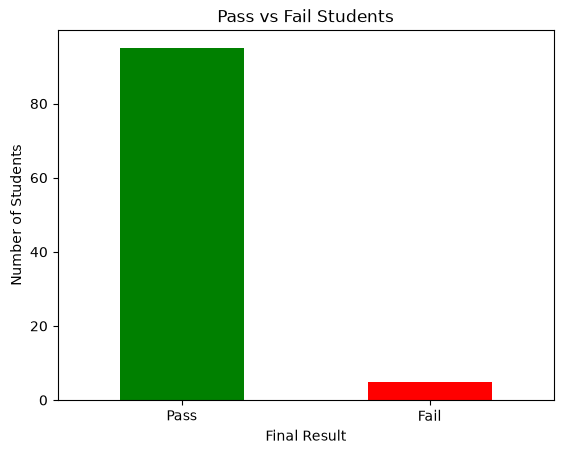

In [6]:
df["Final_Result"].value_counts().plot(kind="bar", color=["green", "red"])
plt.title("Pass vs Fail Students")
plt.xlabel("Final Result")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.show()

In [7]:
X = df.drop("Final_Result", axis=1)
y = df["Final_Result"]

print("Features:", list(X.columns))
print("Target  :", y.name)
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Features: ['Hours_Studied', 'Attendance_Percent', 'Previous_Marks', 'Sleep_Hours']
Target  : Final_Result
Shape of X: (100, 4)
Shape of y: (100,)


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

X_train: (80, 4)
X_test : (20, 4)


In [9]:
imputer = SimpleImputer(strategy="median")
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Preprocessing done!")

Preprocessing done!


In [10]:
model = LogisticRegression()
model.fit(X_train_scaled, y_train)

print("Model trained successfully!")

Model trained successfully!


In [11]:
y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", round(accuracy * 100, 2), "%")
print()

cm = confusion_matrix(y_test, y_pred, labels=["Fail", "Pass"])
print("Confusion Matrix (rows = actual, columns = predicted):")
print(pd.DataFrame(cm, index=["Actual Fail", "Actual Pass"], columns=["Predicted Fail", "Predicted Pass"]))

Accuracy: 95.0 %

Confusion Matrix (rows = actual, columns = predicted):
             Predicted Fail  Predicted Pass
Actual Fail               0               1
Actual Pass               0              19


In [12]:
results = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred})
results["Correct?"] = results["Actual"] == results["Predicted"]
results

,Actual,Predicted,Correct?
0,Pass,Pass,True
1,Pass,Pass,True
2,Pass,Pass,True
3,Pass,Pass,True
4,Pass,Pass,True
5,Pass,Pass,True
6,Pass,Pass,True
7,Pass,Pass,True
8,Pass,Pass,True
9,Pass,Pass,True


In [13]:
# Order: Hours_Studied, Attendance_Percent, Previous_Marks, Sleep_Hours
new_students = pd.DataFrame([
    [6.0, 85.0, 72.0, 7.0],
    [1.5, 58.0, 38.0, 5.0],
    [4.0, 70.0, 55.0, 6.5],
    [8.0, 92.0, 80.0, 7.5],
], columns=X.columns)

new_scaled = scaler.transform(imputer.transform(new_students))
predictions = model.predict(new_scaled)
probabilities = model.predict_proba(new_scaled)

for i in range(len(new_students)):
    row = new_students.iloc[i]
    print(f"Student {i+1}")
    print(f"  Study Hours   : {row['Hours_Studied']}")
    print(f"  Attendance    : {row['Attendance_Percent']}%")
    print(f"  Previous Marks: {row['Previous_Marks']}")
    print(f"  Sleep Hours   : {row['Sleep_Hours']}")
    print(f"  Prediction    : {predictions[i].upper()}")
    print(f"  Chance of Pass: {round(probabilities[i][1] * 100, 1)}%")
    print()

Student 1
  Study Hours   : 6.0
  Attendance    : 85.0%
  Previous Marks: 72.0
  Sleep Hours   : 7.0
  Prediction    : PASS
  Chance of Pass: 99.4%

Student 2
  Study Hours   : 1.5
  Attendance    : 58.0%
  Previous Marks: 38.0
  Sleep Hours   : 5.0
  Prediction    : PASS
  Chance of Pass: 71.4%

Student 3
  Study Hours   : 4.0
  Attendance    : 70.0%
  Previous Marks: 55.0
  Sleep Hours   : 6.5
  Prediction    : PASS
  Chance of Pass: 94.7%

Student 4
  Study Hours   : 8.0
  Attendance    : 92.0%
  Previous Marks: 80.0
  Sleep Hours   : 7.5
  Prediction    : PASS
  Chance of Pass: 99.9%

